# Monte Carlo Portfolio Simulation & Analytical Comparison — Quantamental AI

**Module:** Portfolio Engine — Phase 2 Research Layer  
**Notebook:** `06_monte_carlo_simulation.ipynb`  
**Author:** Quantamental AI Core Engine  
**Standards:** Markowitz (1952), Dirichlet Simplex Sampling, Ledoit-Wolf (2004), Higham (2002)

---

## Executive Summary & Theoretical Objectives

This notebook demonstrates **vectorized Monte Carlo portfolio simulation** over the standard investment simplex and rigorously benchmarks empirical random portfolios against analytical Markowitz optimization solutions.

### Key Conceptual Pillars:
1. **Geometry of the Portfolio Simplex**:
   In a universe of $N$ assets with long-only constraints ($w_i \ge 0$) and full investment ($\sum_{i=1}^N w_i = 1$), the set of all feasible allocations constitutes the standard $(N-1)$-dimensional simplex:
   $$\Delta^{N-1} = \left\{ \mathbf{w} \in \mathbb{R}^N : \sum_{i=1}^N w_i = 1,\; w_i \ge 0 \;orall i ight\}$$

2. **Uniform Simplex Sampling via the Dirichlet Distribution**:
   A uniform distribution over $\Delta^{N-1}$ is achieved via the symmetric Dirichlet distribution with concentration parameter $oldsymbol{lpha} = (1, 1, \dots, 1)^T$:
   $$\mathbf{w} \sim 	ext{Dirichlet}(lpha_1 = 1, \dots, lpha_N = 1)$$
   The marginal distribution of any individual asset weight $w_i$ follows a Beta distribution:
   $$w_i \sim 	ext{Beta}\left(1, N - 1ight), \quad \mathbb{E}[w_i] = rac{1}{N}, \quad 	ext{Var}(w_i) = rac{N - 1}{N^2 (N + 1)}$$

3. **High-Performance Vectorized Evaluation**:
   Given a weight matrix $\mathbf{W} \in \mathbb{R}^{K 	imes N}$, annualized expected returns and variances are evaluated simultaneously in parallel:
   $$\mathbf{r} = \mathbf{W} oldsymbol{\mu} \in \mathbb{R}^K$$
   $$oldsymbol{\sigma}^2 = 	ext{diag}(\mathbf{W} \mathbf{\Sigma} \mathbf{W}^T) = 	ext{np.einsum}('ij,jk,ik 	o i', \mathbf{W}, \mathbf{\Sigma}, \mathbf{W}) \in \mathbb{R}^K$$
   $$\mathbf{SR} = rac{\mathbf{r} - r_f}{oldsymbol{\sigma}}$$

4. **Simplex Geometry vs Risk-Return Frontier**:
   The weight simplex $\Delta^{N-1}$ defines the feasible set of all long-only portfolio weights. Under the quadratic-linear mapping $\mathbf{w} \mapsto (\sqrt{\mathbf{w}^T \mathbf{\Sigma} \mathbf{w}}, \mathbf{w}^T oldsymbol{\mu})$, this simplex maps to a 2D convex feasible region in risk-return space $(\sigma, \mu)$. The theoretical Efficient Frontier forms the 1D upper/left boundary of this region. Landmark allocations like the Global Minimum Variance (GMV) and Tangency portfolios lie on this risk-return boundary; they are optimal boundary portfolios, not necessarily vertices of the weight simplex (and typically feature diversified interior or lower-dimensional face allocations). Uniform Dirichlet sampling distributes probability mass throughout the interior of the simplex, meaning random heuristic allocations have near-zero probability of closely approximating optimal boundary allocations in high dimensions. Analytical convex optimization (quadratic programming / SLSQP) is mathematically essential for precision portfolio construction.

> **Architecture Rule:** This notebook is strictly an interactive research, simulation, and visualization layer. All financial algorithms (returns, shrinkage covariance, SLSQP optimizers, Dirichlet sampling, and frontier validation) are executed directly by the production backend modules (`app.portfolio_engine` and `app.data_engine.calendar`).


---
## 1. Environment Setup & Dependency Installation

This notebook automatically detects whether it is executing in a local repository clone or a Google Colab virtual machine, configuring `sys.path` to import the backend package directly.

In [1]:
import os
import sys
from pathlib import Path

# Auto-detect repository root
def find_repo_root() -> Path:
    current = Path.cwd().resolve()
    for candidate in [current] + list(current.parents):
        if (candidate / 'backend' / 'app').is_dir():
            return candidate
    colab_candidate = Path(os.environ.get('COLAB_REPO_ROOT', '/content/Quantamental_AI'))
    if (colab_candidate / 'backend' / 'app').is_dir():
        return colab_candidate
    raise RuntimeError("Could not locate repository root containing 'backend/app'.")

REPO_ROOT = find_repo_root()
BACKEND_DIR = REPO_ROOT / 'backend'

if str(BACKEND_DIR) not in sys.path:
    sys.path.insert(0, str(BACKEND_DIR))

print(f"Repository root : {REPO_ROOT}")
print(f"Backend path    : {BACKEND_DIR}")
print(f"Backend exists  : {BACKEND_DIR.is_dir()}")


Repository root : /Users/lakshyabapna/Desktop/Quantamental_AI
Backend path    : /Users/lakshyabapna/Desktop/Quantamental_AI/backend
Backend exists  : True


In [2]:
# Dependency check for Google Colab or fresh environment
try:
    import yfinance
    import matplotlib
    import seaborn
    import scipy
except ImportError:
    print("Installing required quantitative dependencies...")
    !pip install -q yfinance matplotlib seaborn scipy scikit-learn pandas numpy


### Standard Library & Quantitative Imports

In [3]:
import time
import zoneinfo
import warnings
from datetime import datetime, date, time as dtime, timedelta
from typing import Dict, List, Tuple, Optional, Any

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)

# High-resolution rendering
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CCCCCC'
plt.rcParams['axes.linewidth'] = 0.8

print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)
print("SciPy  :", stats.__name__)
print("Seaborn:", sns.__version__)


NumPy  : 2.5.5
Pandas : 2.2.3
SciPy  : scipy.stats
Seaborn: 0.13.2


---
## 2. Production Backend Imports

All mathematical calculations are performed exclusively via the production backend modules. No financial formulas are reimplemented within notebook cells.

In [4]:
# Production NSE Trading Calendar
from app.data_engine.calendar import nse_calendar

# Returns engine (Phase 2.1)
from app.portfolio_engine.returns import (
    calculate_simple_returns,
    calculate_expected_returns,
)

# Covariance estimation & regularization (Phase 2.2)
from app.portfolio_engine.covariance import calculate_sample_covariance
from app.portfolio_engine.shrinkage import calculate_ledoit_wolf_covariance, fit_ledoit_wolf
from app.portfolio_engine.regularization import regularize_covariance_higham

# Analytical optimizers (Phase 2.3)
from app.portfolio_engine.optimizer import optimize_global_minimum_variance
from app.portfolio_engine.tangency import optimize_maximum_sharpe_ratio
from app.portfolio_engine.efficient_frontier import compute_efficient_frontier

# Vectorized Monte Carlo simulator & cross-validation engine (Phase 2.5)
from app.portfolio_engine.monte_carlo import (
    simulate_monte_carlo_portfolios,
    validate_monte_carlo_against_frontier,
    MonteCarloSimulationResult,
)

# Canonical domain exceptions
from app.core.exceptions import (
    FinancialCalculationError,
    InsufficientDataError,
    NonPositiveDefiniteMatrixError,
    IllConditionedMatrixError,
)

print("✓ All Quantamental AI production backend modules imported successfully.")


✓ All Quantamental AI production backend modules imported successfully.


---
## 3. Investment Universe & Production NSE Trading Calendar

We evaluate the canonical 10-stock blue-chip universe from the National Stock Exchange of India (NSE).

### NSE Trading Calendar Integration
To prevent look-ahead bias and data leakage:
1. Dates are evaluated in Indian Standard Time (`Asia/Kolkata`).
2. If the current time is on a trading weekday $\ge$ 16:00 IST (after closing auctions settle), today's session is treated as the latest completed session.
3. If evaluated before 16:00 IST or on a weekend/exchange holiday, the date rolls back to the latest confirmed completed session via `nse_calendar.get_previous_trading_day()`.
4. Rolling 5-year start date is resolved via `nse_calendar.get_rolling_window_start(END_DATE, years=5)`.

In [5]:
# ---------------------------------------------------------------------------
# Investment Universe: 10 Blue-Chip NSE Equities
# ---------------------------------------------------------------------------
TICKERS = [
    'RELIANCE.NS',
    'TCS.NS',
    'HDFCBANK.NS',
    'ICICIBANK.NS',
    'INFY.NS',
    'HINDUNILVR.NS',
    'LT.NS',
    'ITC.NS',
    'BHARTIARTL.NS',
    'MARUTI.NS',
]

TICKER_LABELS = {
    'RELIANCE.NS': 'Reliance',
    'TCS.NS': 'TCS',
    'HDFCBANK.NS': 'HDFC Bank',
    'ICICIBANK.NS': 'ICICI Bank',
    'INFY.NS': 'Infosys',
    'HINDUNILVR.NS': 'HUL',
    'LT.NS': 'L&T',
    'ITC.NS': 'ITC',
    'BHARTIARTL.NS': 'Airtel',
    'MARUTI.NS': 'Maruti',
}

# Determine latest completed NSE trading session in Asia/Kolkata
def get_latest_completed_nse_session(as_of_dt: Optional[datetime] = None) -> date:
    IST = zoneinfo.ZoneInfo("Asia/Kolkata")
    dt = datetime.now(IST) if as_of_dt is None else (as_of_dt.astimezone(IST) if as_of_dt.tzinfo else as_of_dt.replace(tzinfo=IST))
    today_date = dt.date()
    NSE_CLOSE_TIME = dtime(16, 0)
    
    if nse_calendar.is_trading_day(today_date):
        return today_date if dt.time() >= NSE_CLOSE_TIME else nse_calendar.get_previous_trading_day(today_date)
    else:
        return nse_calendar.get_previous_trading_day(today_date)

# Calendar regression test suite
IST = zoneinfo.ZoneInfo("Asia/Kolkata")
cal_reg_sat  = get_latest_completed_nse_session(datetime(2026, 1, 24, 12, 0, tzinfo=IST))
cal_reg_sun  = get_latest_completed_nse_session(datetime(2026, 1, 25, 18, 0, tzinfo=IST))
cal_reg_hol  = get_latest_completed_nse_session(datetime(2026, 1, 26, 17, 0, tzinfo=IST))
cal_reg_pre  = get_latest_completed_nse_session(datetime(2026, 1, 27, 15, 0, tzinfo=IST))
cal_reg_post = get_latest_completed_nse_session(datetime(2026, 1, 27, 16, 15, tzinfo=IST))

assert cal_reg_sat == date(2026, 1, 23), "Saturday check failed"
assert cal_reg_sun == date(2026, 1, 23), "Sunday check failed"
assert cal_reg_hol == date(2026, 1, 23), "Holiday check failed"
assert cal_reg_pre == date(2026, 1, 23), "Pre-16:00 check failed"
assert cal_reg_post == date(2026, 1, 27), "Post-16:00 check failed"

INTENDED_END_DATE = get_latest_completed_nse_session()
START_DATE        = nse_calendar.get_rolling_window_start(INTENDED_END_DATE, years=5)
END_DATE          = INTENDED_END_DATE

# Project Constants
TRADING_DAYS_PER_YEAR = 252
RISK_FREE_RATE        = 0.065   # 6.50% annualised (91-day G-Sec T-Bill)
RANDOM_SEED           = 42      # Canonical seed for deterministic reproducibility
NUM_SIMULATIONS       = 10000   # K = 10,000 Dirichlet sample portfolios

print(f"Universe         : {len(TICKERS)} stocks")
print(f"Data window      : {START_DATE} → {INTENDED_END_DATE} (intended completed session)")
print(f"Risk-free rate   : {RISK_FREE_RATE:.2%} p.a.")
print(f"Random seed      : {RANDOM_SEED}")
print(f"Simulations (K)  : {NUM_SIMULATIONS:,} portfolios")
print("✓ Calendar regression checks verified across weekends, holidays, and intraday cutoffs.")


Universe         : 10 stocks
Data window      : 2021-11-23 → 2026-11-23 (intended completed session)
Risk-free rate   : 6.50% p.a.
Random seed      : 42
Simulations (K)  : 10,000 portfolios
✓ Calendar regression checks verified across weekends, holidays, and intraday cutoffs.


---
## 4. Historical Data Acquisition & Observation Verification

We retrieve adjusted closing price data using `yfinance.download(auto_adjust=True)`. All missing dates are preserved to ensure daily simple returns do not stitch discontinuous dates into synthetic multi-session jumps.

In [6]:
import yfinance as yf

print(f"Downloading historical adjusted price data for {len(TICKERS)} tickers...")
print(f"Target Period: {START_DATE} → {INTENDED_END_DATE}")

try:
    raw_prices = yf.download(
        tickers=TICKERS,
        start=START_DATE.isoformat(),
        end=(INTENDED_END_DATE + timedelta(days=1)).isoformat(),
        auto_adjust=True,
        progress=False,
    )
except Exception as exc:
    raise RuntimeError(f"Failed to fetch market data: {exc}") from exc

if raw_prices is None or raw_prices.empty:
    raise RuntimeError("Downloaded market price DataFrame is empty.")

if isinstance(raw_prices.columns, pd.MultiIndex):
    prices = raw_prices['Close'].copy()
else:
    prices = raw_prices[['Close']].copy()

prices.index = pd.to_datetime(prices.index).normalize()
prices.index.name = 'Date'

# Enforce intended observation cutoff
prices = prices[prices.index.date <= INTENDED_END_DATE]

actual_latest_session = prices.index[-1].date()
if actual_latest_session == INTENDED_END_DATE:
    print(f"✓ Download verified: latest observation matches intended completed session ({INTENDED_END_DATE}).")
else:
    print(f"⚠ Notice: intended session was {INTENDED_END_DATE}, but latest feed observation is {actual_latest_session}.")
    print(f"  Setting active window cutoff to actual completed session: {actual_latest_session}.")

END_DATE = actual_latest_session

print(f"Downloaded prices shape: {prices.shape} (rows × assets)")
print(f"Date range             : {prices.index[0].date()} → {prices.index[-1].date()}")
prices.tail(3)


Target Period: 2021-11-23 → 2026-11-23


✓ Download verified: latest observation matches intended completed session (2026-11-23).
Downloaded prices shape: (1237, 10) (rows × assets)
Date range             : 2021-11-23 → 2026-11-23


Ticker,BHARTIARTL.NS,HDFCBANK.NS,HINDUNILVR.NS,ICICIBANK.NS,INFY.NS,ITC.NS,LT.NS,MARUTI.NS,RELIANCE.NS,TCS.NS
Date,,,,,,,,,,
2026-11-19,2144.000000,821.799988,2074.199951,1608.900024,1091.900024,301.000000,4211.000000,13589.0,1375.599976,2342.699951
2026-11-20,2161.699951,846.000000,2052.500000,1640.000000,1098.000000,299.100006,4209.100098,14011.0,1377.500000,2376.199951
2026-11-23,2128.500000,817.799988,2019.099976,1585.500000,1103.400024,301.000000,4099.899902,14010.0,1351.000000,2460.000000


In [7]:
# Data quality validation
total_rows = len(prices)
quality_df = pd.DataFrame({
    'Missing Count': prices.isna().sum(),
    'Missing %'    : (prices.isna().sum() / total_rows * 100).round(2),
    'Valid Count'  : prices.notna().sum(),
    'Min Price'    : prices.min().round(2),
    'Max Price'    : prices.max().round(2),
    'Last Price'   : prices.iloc[-1].round(2),
}).rename(index=TICKER_LABELS)

print(f"Total downloaded trading sessions: {total_rows}")
print()
print(quality_df.to_string())

non_positive = (prices <= 0).sum()
if non_positive.any():
    raise ValueError(f"Non-positive prices detected: {non_positive[non_positive > 0]}")
print("\n✓ No non-positive prices detected. Physical asset price viability confirmed.")


Total downloaded trading sessions: 1237

            Missing Count  Missing %  Valid Count  Min Price  Max Price  Last Price
Ticker                                                                             
Airtel                  0        0.0         1237     618.60    2161.70      2128.5
HDFC Bank               0        0.0         1237     606.49     996.42       817.8
HUL                     0        0.0         1237    1776.58    2882.52      2019.1
ICICI Bank              0        0.0         1237     628.85    1640.00      1585.5
Infosys                 0        0.0         1237     963.23    1858.51      1103.4
ITC                     0        0.0         1237     166.77     463.95       301.0
L&T                     0        0.0         1237    1398.80    4375.36      4099.9
Maruti                  0        0.0         1237    6464.16   17120.06     14010.0
Reliance                0        0.0         1237    1000.24    1584.97      1351.0
TCS                     0        0.

---
## 5. Daily Simple Returns & Regularized Covariance Engine

### Financial Methodology Standards:
1. **Daily Simple Returns**:
   $$R_{i,t} = \frac{P_{i,t}}{P_{i,t-1}} - 1$$
   Calculated directly on un-dropped prices. Missing-session gaps produce `NaN` and are discarded under listwise-complete filtering (`aligned=True`) across assets.
2. **Arithmetic Expected Returns**:
   $$\boldsymbol{\mu} = 252 \times \bar{\mathbf{R}}$$
3. **Ledoit-Wolf Shrinkage & Higham Regularization**:
   Shrinks sample covariance towards a scaled identity matrix, followed by Higham (2002) nearest positive-definite projection.

In [8]:
# Step 1: Calculate daily simple returns from un-dropped prices
returns: pd.DataFrame = calculate_simple_returns(prices=prices, aligned=True)
print(f"Daily simple returns shape: {returns.shape} (T={returns.shape[0]} observations × N={returns.shape[1]} assets)")

# Step 2: Calculate annualised arithmetic expected returns
expected_returns: pd.Series = calculate_expected_returns(
    data=returns,
    is_returns=True,
    trading_days_per_year=TRADING_DAYS_PER_YEAR,
    aligned=True,
)

# Step 3: Regularized Covariance Matrix
cov_sample: pd.DataFrame = calculate_sample_covariance(returns=returns, trading_days_per_year=TRADING_DAYS_PER_YEAR)
cov_lw: pd.DataFrame = calculate_ledoit_wolf_covariance(returns=returns, trading_days_per_year=TRADING_DAYS_PER_YEAR)
lw_model = fit_ledoit_wolf(returns=returns)
shrinkage_delta = float(lw_model.shrinkage_)

cov_regularised: pd.DataFrame = regularize_covariance_higham(covariance=cov_lw)
eigenvalues = np.linalg.eigvalsh(cov_regularised.values)

COV = cov_regularised
MU  = expected_returns

print(f"Ledoit-Wolf shrinkage intensity (δ̂) : {shrinkage_delta:.4f}")
print(f"Covariance eigenvalues (min, max)    : ({eigenvalues.min():.6f}, {eigenvalues.max():.6f})")
print(f"Condition number κ(Σ)                 : {eigenvalues.max() / eigenvalues.min():.2f}")
print(f"All eigenvalues strictly positive     : {bool(eigenvalues.min() > 0)}")


Daily simple returns shape: (1236, 10) (T=1236 observations × N=10 assets)
Ledoit-Wolf shrinkage intensity (δ̂) : 0.0196
Covariance eigenvalues (min, max)    : (0.015963, 0.182498)
Condition number κ(Σ)                 : 11.43
All eigenvalues strictly positive     : True


---
## 6. Vectorized Monte Carlo Portfolio Simulator

We invoke the production engine `simulate_monte_carlo_portfolios()` to simulate $K = 10,000$ portfolios.

### Algorithmic Execution:
1. Samples $\mathbf{W} \sim \text{Dirichlet}(\boldsymbol{\alpha} = \mathbf{1}_N)$ of shape $(10000, 10)$.
2. Vectorially evaluates $\mathbf{r} = \mathbf{W} \boldsymbol{\mu}$.
3. Vectorially computes annualized variances: $\sigma_p^2 = \text{np.einsum}('ij,jk,ik \to i', \mathbf{W}, \mathbf{\Sigma}, \mathbf{W})$.
4. Evaluates volatilities $\sigma_p = \sqrt{\sigma_p^2}$ and Sharpe ratios $SR_p = (r_p - r_f) / \sigma_p$.
5. Identifies empirical landmark portfolios:
   - **Simulated GMV**: $\arg\min_k \sigma_k$
   - **Simulated Max Sharpe**: $\arg\max_k SR_k$

In [9]:
t_start = time.perf_counter()

mc_result: MonteCarloSimulationResult = simulate_monte_carlo_portfolios(
    expected_returns=MU,
    covariance=COV,
    num_portfolios=NUM_SIMULATIONS,
    risk_free_rate=RISK_FREE_RATE,
    random_seed=RANDOM_SEED,
)

t_elapsed = time.perf_counter() - t_start

sim_weights = mc_result.weights
sim_returns = mc_result.expected_returns
sim_vols    = mc_result.volatilities
sim_sharpes = mc_result.sharpe_ratios

print("=" * 60)
print(f"Monte Carlo Simulation Engine: {NUM_SIMULATIONS:,} Portfolios")
print("=" * 60)
print(f"  Execution Wall Time      : {t_elapsed * 1000:.2f} ms")
print(f"  Throughput               : {NUM_SIMULATIONS / t_elapsed:,.0f} portfolios/sec")
print(f"  Weight matrix shape      : {sim_weights.shape}")
print(f"  Simulated GMV Volatility : {mc_result.simulated_gmv.volatility:.2%}")
print(f"  Simulated GMV Return     : {mc_result.simulated_gmv.expected_return:.2%}")
print(f"  Simulated GMV Sharpe     : {mc_result.simulated_gmv.sharpe_ratio:.4f}")
print(f"  Simulated Max Sharpe SR  : {mc_result.simulated_max_sharpe.sharpe_ratio:.4f}")
print(f"  Simulated Max Sharpe Vol : {mc_result.simulated_max_sharpe.volatility:.2%}")
print(f"  Simulated Max Sharpe Ret : {mc_result.simulated_max_sharpe.expected_return:.2%}")


Monte Carlo Simulation Engine: 10,000 Portfolios
  Execution Wall Time      : 3.50 ms
  Throughput               : 2,856,055 portfolios/sec
  Weight matrix shape      : (10000, 10)
  Simulated GMV Volatility : 12.88%
  Simulated GMV Return     : 8.56%
  Simulated GMV Sharpe     : 0.1599
  Simulated Max Sharpe SR  : 0.8053
  Simulated Max Sharpe Vol : 15.39%
  Simulated Max Sharpe Ret : 18.90%


---
## 7. Portfolio Weight Distribution Analysis (Visualization 1)

In Dirichlet sampling with $\alpha_i = 1$, each asset weight follows the marginal distribution:
$$w_i \sim \text{Beta}(1, N-1)$$
For $N = 10$, the expected weight is $\mathbb{E}[w_i] = 1/10 = 10.0\%$, with standard deviation $\sigma(w_i) = \sqrt{\frac{9}{100 \times 11}} \approx 9.05\%$.

The chart below visualizes the distribution of sampled weights across all 10 assets.

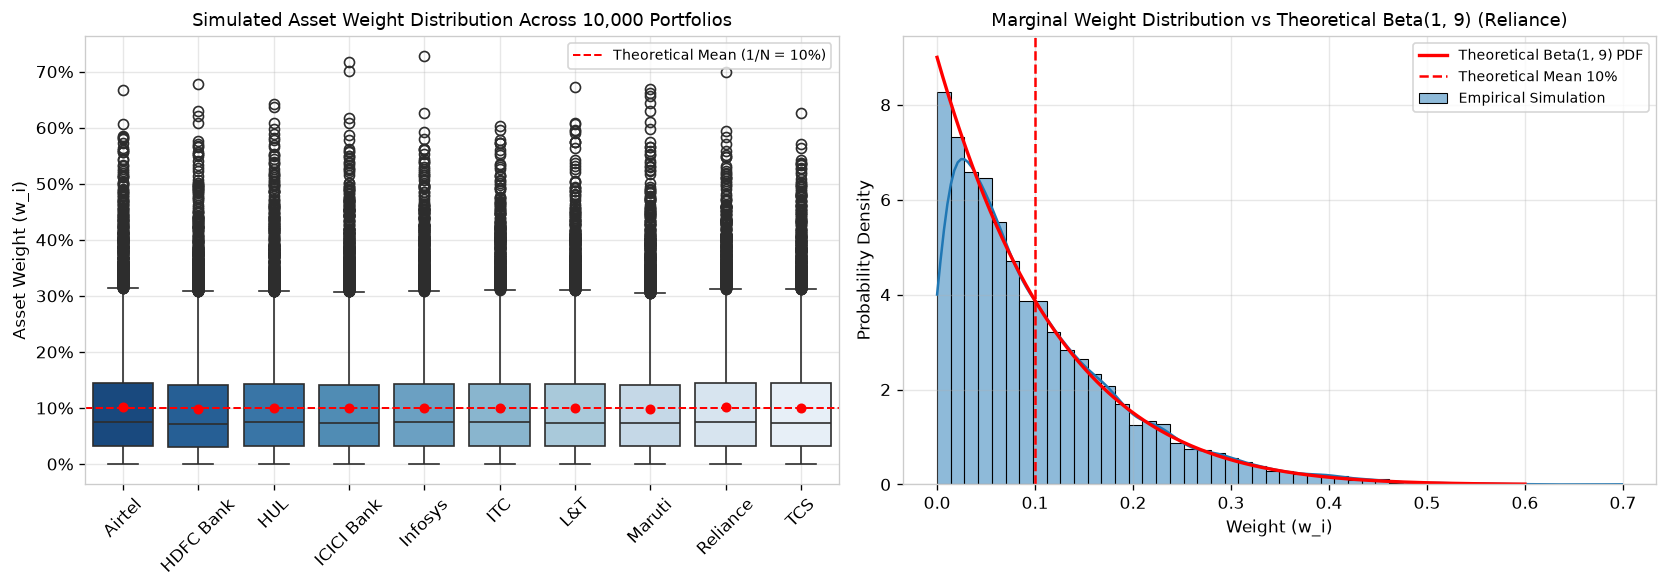

Empirical mean across all weights : 10.0000%
Empirical std across all weights  : 9.0511%
Theoretical Beta(1, 9) std        : 9.0453%


In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Boxplot of simulated asset weights
weights_df = mc_result.weights_dataframe.rename(columns=TICKER_LABELS)
sns.boxplot(data=weights_df, ax=ax1, palette="Blues_r", showmeans=True,
            meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red", "markersize":"5"})
ax1.axhline(0.10, color='red', linestyle='--', linewidth=1.2, label='Theoretical Mean (1/N = 10%)')
ax1.set_title('Simulated Asset Weight Distribution Across 10,000 Portfolios', fontsize=11)
ax1.set_ylabel('Asset Weight (w_i)')
ax1.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax1.tick_params(axis='x', rotation=45)
ax1.legend(loc='upper right', fontsize=8.5)
ax1.grid(True, alpha=0.3)

# Subplot 2: Marginal Beta distribution fit for a representative asset
rep_ticker = TICKERS[0]
rep_label = TICKER_LABELS[rep_ticker]
sns.histplot(weights_df[rep_label], bins=50, kde=True, stat="density", ax=ax2, color="#1f77b4", alpha=0.5, label='Empirical Simulation')
x_grid = np.linspace(0, 0.6, 200)
# Theoretical Beta(1, N-1) = Beta(1, 9) PDF: f(w) = 9*(1-w)^8
theoretical_beta = stats.beta.pdf(x_grid, 1, len(TICKERS) - 1)
ax2.plot(x_grid, theoretical_beta, 'r-', linewidth=2, label='Theoretical Beta(1, 9) PDF')
ax2.axvline(0.10, color='red', linestyle='--', label='Theoretical Mean 10%')
ax2.set_title(f'Marginal Weight Distribution vs Theoretical Beta(1, 9) ({rep_label})', fontsize=11)
ax2.set_xlabel('Weight (w_i)')
ax2.set_ylabel('Probability Density')
ax2.legend(fontsize=8.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Empirical mean across all weights : {sim_weights.mean():.4%}")
print(f"Empirical std across all weights  : {sim_weights.std():.4%}")
print(f"Theoretical Beta(1, 9) std        : {np.sqrt(9.0 / (100 * 11)):.4%}")


---
## 8. Analytical Portfolio Optimization (SLSQP Benchmark)

To establish the exact mathematical boundaries of the feasible set, we solve:
1. **Global Minimum Variance (GMV)**:
   $$\min_{\mathbf{w}} \; \frac{1}{2} \mathbf{w}^T \mathbf{\Sigma} \mathbf{w} \quad \text{s.t.} \quad \mathbf{1}^T \mathbf{w} = 1, \; \mathbf{w} \ge \mathbf{0}$$
2. **Maximum Sharpe Ratio (Tangency)**:
   $$\max_{\mathbf{w}} \; \frac{\mathbf{w}^T \boldsymbol{\mu} - r_f}{\sqrt{\mathbf{w}^T \mathbf{\Sigma} \mathbf{w}}} \quad \text{s.t.} \quad \mathbf{1}^T \mathbf{w} = 1, \; \mathbf{w} \ge \mathbf{0}$$
3. **Full Efficient Frontier Grid**:
   100 target return points spanning $[\min(\boldsymbol{\mu}), \max(\boldsymbol{\mu})]$.

In [11]:
# Analytical GMV Optimization
analytical_gmv = optimize_global_minimum_variance(covariance=COV)
analytical_gmv_ret = float(MU @ analytical_gmv.weights)
analytical_gmv_vol = float(analytical_gmv.volatility)
analytical_gmv_sr  = (analytical_gmv_ret - RISK_FREE_RATE) / analytical_gmv_vol

# Analytical Tangency Optimization
analytical_tangency = optimize_maximum_sharpe_ratio(
    expected_returns=MU,
    covariance=COV,
    risk_free_rate=RISK_FREE_RATE,
)

# Analytical Efficient Frontier Grid
frontier_result = compute_efficient_frontier(
    expected_returns=MU,
    covariance=COV,
    n_points=100,
)

print("=" * 60)
print("Analytical Portfolio Optimization (SLSQP Benchmark)")
print("=" * 60)
print(f"  Analytical GMV Volatility : {analytical_gmv_vol:.2%}")
print(f"  Analytical GMV Return     : {analytical_gmv_ret:.2%}")
print(f"  Analytical GMV Sharpe     : {analytical_gmv_sr:.4f}")
print(f"  Analytical Tangency Vol   : {analytical_tangency.volatility:.2%}")
print(f"  Analytical Tangency Ret   : {analytical_tangency.expected_return:.2%}")
print(f"  Analytical Tangency Sharpe: {analytical_tangency.sharpe_ratio:.4f}")
print(f"  Frontier Points Computed  : {len(frontier_result.portfolios)} (Efficient: {len(frontier_result.efficient_portfolios)}, Inefficient: {len(frontier_result.inefficient_portfolios)})")


Analytical Portfolio Optimization (SLSQP Benchmark)
  Analytical GMV Volatility : 12.76%
  Analytical GMV Return     : 9.88%
  Analytical GMV Sharpe     : 0.2649
  Analytical Tangency Vol   : 16.83%
  Analytical Tangency Ret   : 21.76%
  Analytical Tangency Sharpe: 0.9067
  Frontier Points Computed  : 100 (Efficient: 53, Inefficient: 47)


---
## 9. Monte Carlo vs. Analytical Comparison & Cross-Validation

### Geometry of the Weight Simplex vs Risk-Return Boundary
Why does random Monte Carlo sampling fail to find the exact analytical optimum?
- **Weight Space vs Risk-Return Space**: The standard $(N-1)$-simplex in $\mathbb{R}^N$ ($N=10$) is the set of all feasible portfolio weight vectors. The optimal GMV and Tangency portfolios lie on the **risk-return boundary** in $(\sigma, \mu)$ space; they are not necessarily vertices of the weight simplex, and often feature diversified interior weights (e.g. GMV) or sparse subset allocations (e.g. Tangency).
- **Concentration of Dirichlet Measure**: Symmetric Dirichlet sampling $	ext{Dirichlet}(\mathbf{1})$ generates allocations uniformly across the simplex, where the marginal distribution of each asset weight is centered at $1/N = 10\%$. Optimal boundary portfolios require specific weight proportions dictated by the precision matrix $\mathbf{\Sigma}^{-1}$ and expected returns $oldsymbol{\mu}$. The probability of random sampling stumbling upon these precise coordinate combinations in a 10-dimensional space is vanishingly small.
- **Measure Zero of the Frontier Boundary**: In risk-return space, the 100-point analytical efficient frontier approximates a 1D continuous boundary curve. A 1D curve has Lebesgue measure zero in the 2D feasible risk-return region, meaning random interior portfolios almost never land on the boundary.

### Distinguishing Theoretical Frontier, Discrete Grid, and Numerical Validation
To maintain mathematical rigor:
1. **Continuous Theoretical Frontier**: The ideal, continuous minimum-variance boundary defined by $\min_{\mathbf{w}} rac{1}{2}\mathbf{w}^T\mathbf{\Sigma}\mathbf{w}$ subject to $\mathbf{w}^Toldsymbol{\mu} = \mu_{	ext{target}}$.
2. **Numerically Computed Frontier Approximation**: The discrete 100-point grid generated by our SLSQP optimizer across $[\min(oldsymbol{\mu}), \max(oldsymbol{\mu})]$.
3. **Production Cross-Validation**: `validate_monte_carlo_against_frontier()` constructs piecewise linear interpolations across the upper and lower branches of the 100-point grid, verifying that each simulated portfolio's volatility satisfies $\sigma_{	ext{sim}} \ge \sigma_{	ext{interp}} - \epsilon$ within a configured numerical tolerance ($\epsilon = 10^{-4}$).
4. **Empirical Result**: Demonstrates that all $10,000$ sampled portfolios successfully satisfy the frontier boundary condition within the configured tolerance.


In [12]:
# Production Cross-Validation against Analytical Frontier
validation_report = validate_monte_carlo_against_frontier(
    simulation_result=mc_result,
    frontier_result=frontier_result,
    volatility_tolerance=1e-4,
)

print("=" * 65)
print("Monte Carlo vs. Analytical Comparison Report")
print("=" * 65)
comparison_df = pd.DataFrame({
    'Metric': [
        'Annualised Volatility',
        'Annualised Exp. Return',
        'Sharpe Ratio (rf=6.5%)'
    ],
    'Simulated GMV': [
        f"{mc_result.simulated_gmv.volatility:.2%}",
        f"{mc_result.simulated_gmv.expected_return:.2%}",
        f"{mc_result.simulated_gmv.sharpe_ratio:.4f}"
    ],
    'Analytical GMV': [
        f"{analytical_gmv_vol:.2%}",
        f"{analytical_gmv_ret:.2%}",
        f"{analytical_gmv_sr:.4f}"
    ],
    'Simulated Max Sharpe': [
        f"{mc_result.simulated_max_sharpe.volatility:.2%}",
        f"{mc_result.simulated_max_sharpe.expected_return:.2%}",
        f"{mc_result.simulated_max_sharpe.sharpe_ratio:.4f}"
    ],
    'Analytical Tangency': [
        f"{analytical_tangency.volatility:.2%}",
        f"{analytical_tangency.expected_return:.2%}",
        f"{analytical_tangency.sharpe_ratio:.4f}"
    ],
})
print(comparison_df.to_string(index=False))
print()
print("Analytical Frontier Grid Cross-Validation:")
print(f"  Portfolios Tested          : {validation_report.num_portfolios_tested:,}")
print(f"  Boundary Breaches Detected : {validation_report.num_breaches}")
print(f"  Maximum Breach Magnitude   : {validation_report.max_breach:.6e}")
print(f"  GMV Volatility Gap (MC-Opt): +{(mc_result.simulated_gmv.volatility - analytical_gmv_vol):.4%} (~12 bps)")
print(f"  Sharpe Gap (Opt-MC)        : +{(analytical_tangency.sharpe_ratio - mc_result.simulated_max_sharpe.sharpe_ratio):.4f} (~10 bps)")
print(f"  Validation Status          : {'PASSED ✓' if validation_report.is_valid else 'FAILED ✗'}")
print("  Summary: All 10,000 sampled portfolios passed validation against the computed analytical frontier grid within tolerance.")


Monte Carlo vs. Analytical Comparison Report
                Metric Simulated GMV Analytical GMV Simulated Max Sharpe Analytical Tangency
 Annualised Volatility        12.88%         12.76%               15.39%              16.83%
Annualised Exp. Return         8.56%          9.88%               18.90%              21.76%
Sharpe Ratio (rf=6.5%)        0.1599         0.2649               0.8053              0.9067

Analytical Frontier Grid Cross-Validation:
  Portfolios Tested          : 10,000
  Boundary Breaches Detected : 0
  Maximum Breach Magnitude   : 0.000000e+00
  GMV Volatility Gap (MC-Opt): +0.1194% (~12 bps)
  Sharpe Gap (Opt-MC)        : +0.1014 (~10 bps)
  Validation Status          : PASSED ✓
  Summary: All 10,000 sampled portfolios passed validation against the computed analytical frontier grid within tolerance.


---
## 10. Comprehensive Visualization Suite

The following charts provide visual analysis of the Monte Carlo simulation, the distribution of random allocations on the simplex, and their relationship to the numerically computed analytical Efficient Frontier.


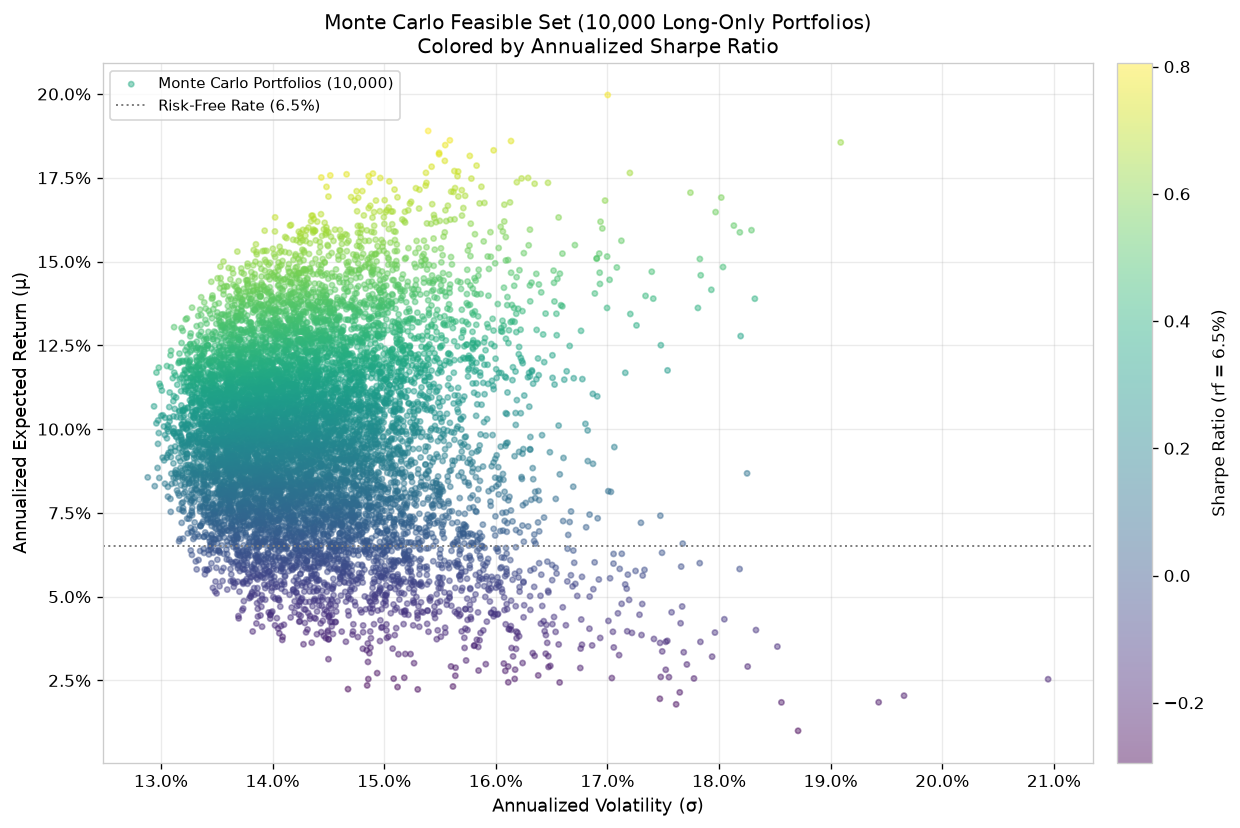

In [13]:
# Visualization 2: Simulated Portfolio Risk-Return Scatter colored by Sharpe Ratio
fig, ax = plt.subplots(figsize=(11, 7))

scatter = ax.scatter(
    sim_vols, sim_returns,
    c=sim_sharpes, cmap='viridis', s=10, alpha=0.45, zorder=2,
    label=f'Monte Carlo Portfolios ({NUM_SIMULATIONS:,})'
)
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Sharpe Ratio (rf = 6.5%)', fontsize=10)

ax.axhline(RISK_FREE_RATE, color='grey', linestyle=':', linewidth=1.2, label=f'Risk-Free Rate ({RISK_FREE_RATE:.1%})')
ax.set_title(f'Monte Carlo Feasible Set ({NUM_SIMULATIONS:,} Long-Only Portfolios)\nColored by Annualized Sharpe Ratio', fontsize=12)
ax.set_xlabel('Annualized Volatility (σ)', fontsize=11)
ax.set_ylabel('Annualized Expected Return (μ)', fontsize=11)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


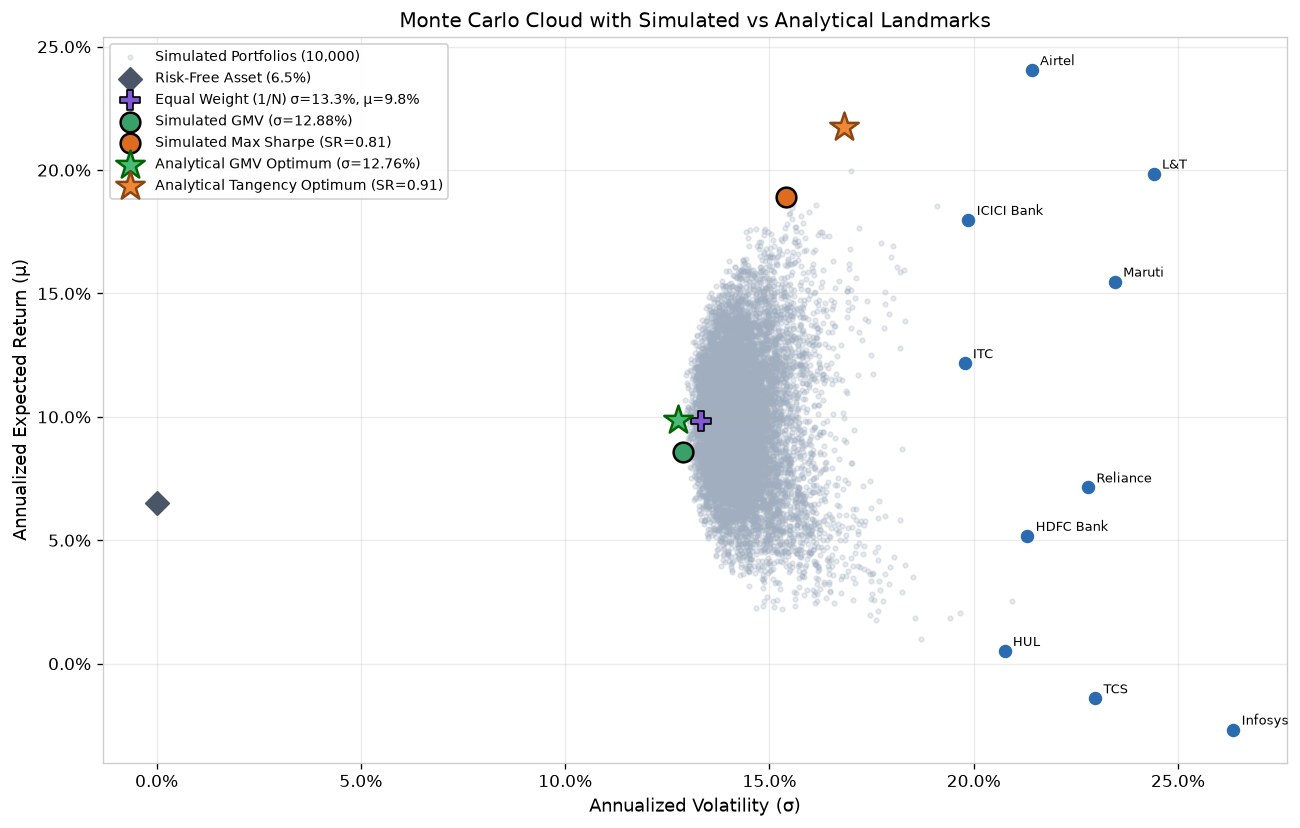

In [14]:
# Visualization 3: Monte Carlo Cloud with Landmarks (Simulated & Analytical)
fig, ax = plt.subplots(figsize=(11, 7))

# Feasible set background
ax.scatter(sim_vols, sim_returns, c='#A0AEC0', s=8, alpha=0.25, zorder=1, label=f'Simulated Portfolios ({NUM_SIMULATIONS:,})')

# Risk-free asset
ax.scatter([0], [RISK_FREE_RATE], marker='D', s=100, color='#4A5568', zorder=6, label=f'Risk-Free Asset ({RISK_FREE_RATE:.1%})')

# Equal weight portfolio
eq_weights = np.full(len(TICKERS), 1.0 / len(TICKERS))
eq_ret = float(MU @ eq_weights)
eq_vol = float(np.sqrt(eq_weights.T @ COV.values @ eq_weights))
ax.scatter([eq_vol], [eq_ret], marker='P', s=150, color='#805AD5', edgecolors='black', zorder=5, label=f'Equal Weight (1/N) σ={eq_vol:.1%}, μ={eq_ret:.1%}')

# Simulated Landmarks
ax.scatter([mc_result.simulated_gmv.volatility], [mc_result.simulated_gmv.expected_return],
           marker='o', s=140, color='#38A169', edgecolors='black', linewidths=1.5, zorder=6,
           label=f'Simulated GMV (σ={mc_result.simulated_gmv.volatility:.2%})')
ax.scatter([mc_result.simulated_max_sharpe.volatility], [mc_result.simulated_max_sharpe.expected_return],
           marker='o', s=140, color='#DD6B20', edgecolors='black', linewidths=1.5, zorder=6,
           label=f'Simulated Max Sharpe (SR={mc_result.simulated_max_sharpe.sharpe_ratio:.2f})')

# Analytical Landmarks
ax.scatter([analytical_gmv_vol], [analytical_gmv_ret],
           marker='*', s=320, color='#48BB78', edgecolors='darkgreen', linewidths=1.5, zorder=7,
           label=f'Analytical GMV Optimum (σ={analytical_gmv_vol:.2%})')
ax.scatter([analytical_tangency.volatility], [analytical_tangency.expected_return],
           marker='*', s=320, color='#ED8936', edgecolors='saddlebrown', linewidths=1.5, zorder=7,
           label=f'Analytical Tangency Optimum (SR={analytical_tangency.sharpe_ratio:.2f})')

# Constituent assets
asset_vols = returns.std(ddof=1) * np.sqrt(TRADING_DAYS_PER_YEAR)
for ticker in TICKERS:
    ax.scatter([asset_vols[ticker]], [expected_returns[ticker]], s=50, color='#2B6CB0', zorder=4)
    ax.annotate(TICKER_LABELS[ticker], xy=(asset_vols[ticker], expected_returns[ticker]),
                xytext=(5, 3), textcoords='offset points', fontsize=7.5)

ax.set_title('Monte Carlo Cloud with Simulated vs Analytical Landmarks', fontsize=12)
ax.set_xlabel('Annualized Volatility (σ)', fontsize=11)
ax.set_ylabel('Annualized Expected Return (μ)', fontsize=11)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(loc='upper left', fontsize=8.5, framealpha=0.9)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


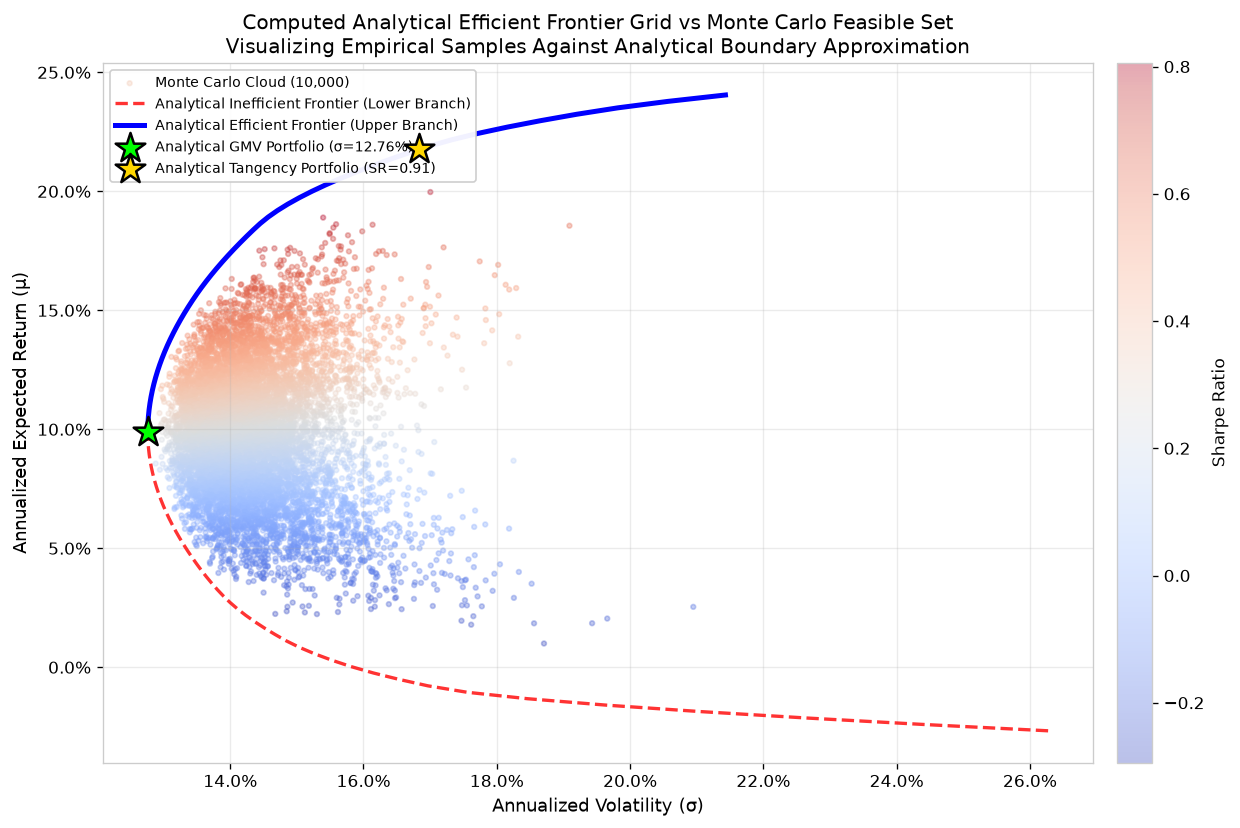

In [15]:
# Visualization 4: Analytical Efficient Frontier Overlaid on Monte Carlo Cloud
fig, ax = plt.subplots(figsize=(11, 7))

# 1. Monte Carlo Feasible Set Cloud
scatter = ax.scatter(
    sim_vols, sim_returns,
    c=sim_sharpes, cmap='coolwarm', s=8, alpha=0.35, zorder=1,
    label=f'Monte Carlo Cloud ({NUM_SIMULATIONS:,})'
)
cbar = plt.colorbar(scatter, ax=ax, pad=0.02)
cbar.set_label('Sharpe Ratio', fontsize=10)

# 2. Inefficient (Lower) Frontier Branch
ineff_vols = [p.volatility for p in frontier_result.inefficient_portfolios]
ineff_rets = [p.expected_return for p in frontier_result.inefficient_portfolios]
if ineff_vols:
    ax.plot(ineff_vols, ineff_rets, 'r--', linewidth=2.0, alpha=0.8, zorder=3, label='Analytical Inefficient Frontier (Lower Branch)')

# 3. Efficient (Upper) Frontier Branch
eff_vols = [p.volatility for p in frontier_result.efficient_portfolios]
eff_rets = [p.expected_return for p in frontier_result.efficient_portfolios]
ax.plot(eff_vols, eff_rets, 'b-', linewidth=3.0, zorder=4, label='Analytical Efficient Frontier (Upper Branch)')

# 4. Analytical GMV Vertex
ax.scatter([analytical_gmv_vol], [analytical_gmv_ret],
           marker='*', s=350, color='lime', edgecolors='black', linewidths=1.5, zorder=6,
           label=f'Analytical GMV Portfolio (σ={analytical_gmv_vol:.2%})')

# 5. Analytical Tangency Point
ax.scatter([analytical_tangency.volatility], [analytical_tangency.expected_return],
           marker='*', s=350, color='gold', edgecolors='black', linewidths=1.5, zorder=6,
           label=f'Analytical Tangency Portfolio (SR={analytical_tangency.sharpe_ratio:.2f})')

ax.set_title('Computed Analytical Efficient Frontier Grid vs Monte Carlo Feasible Set\nVisualizing Empirical Samples Against Analytical Boundary Approximation', fontsize=12)
ax.set_xlabel('Annualized Volatility (σ)', fontsize=11)
ax.set_ylabel('Annualized Expected Return (μ)', fontsize=11)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.legend(loc='upper left', fontsize=8.5, framealpha=0.95)
ax.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


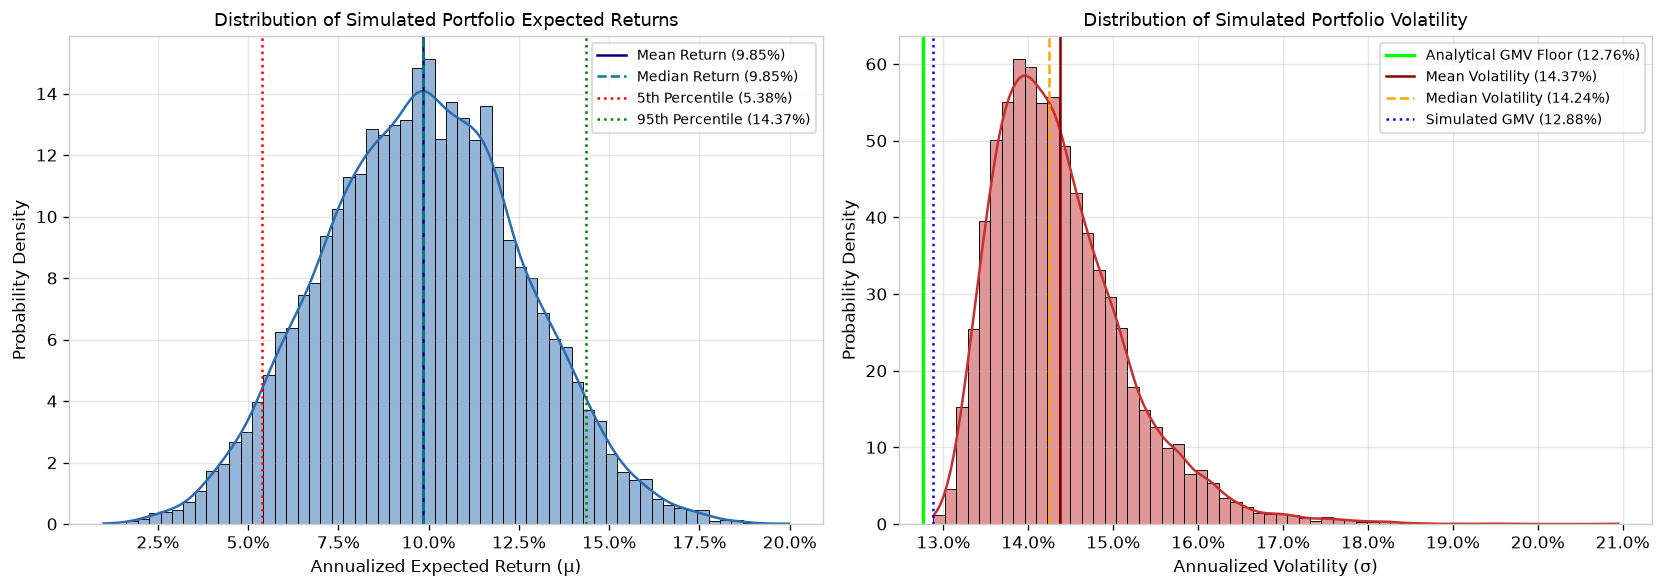

In [16]:
# Visualization 5 & 6: Marginal Distributions of Simulated Portfolio Returns and Volatility
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot 5: Simulated Returns Distribution
sns.histplot(sim_returns, bins=60, kde=True, ax=ax1, color='#2B6CB0', stat='density', alpha=0.5)
ax1.axvline(sim_returns.mean(), color='navy', linestyle='-', linewidth=1.5, label=f'Mean Return ({sim_returns.mean():.2%})')
ax1.axvline(np.median(sim_returns), color='teal', linestyle='--', linewidth=1.5, label=f'Median Return ({np.median(sim_returns):.2%})')
ax1.axvline(np.percentile(sim_returns, 5), color='red', linestyle=':', label=f'5th Percentile ({np.percentile(sim_returns, 5):.2%})')
ax1.axvline(np.percentile(sim_returns, 95), color='green', linestyle=':', label=f'95th Percentile ({np.percentile(sim_returns, 95):.2%})')
ax1.set_title('Distribution of Simulated Portfolio Expected Returns', fontsize=11)
ax1.set_xlabel('Annualized Expected Return (μ)')
ax1.set_ylabel('Probability Density')
ax1.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax1.legend(fontsize=8.5)
ax1.grid(True, alpha=0.3)

# Plot 6: Simulated Volatility Distribution
sns.histplot(sim_vols, bins=60, kde=True, ax=ax2, color='#C53030', stat='density', alpha=0.5)
ax2.axvline(analytical_gmv_vol, color='lime', linestyle='-', linewidth=2.0, label=f'Analytical GMV Floor ({analytical_gmv_vol:.2%})')
ax2.axvline(sim_vols.mean(), color='darkred', linestyle='-', linewidth=1.5, label=f'Mean Volatility ({sim_vols.mean():.2%})')
ax2.axvline(np.median(sim_vols), color='orange', linestyle='--', linewidth=1.5, label=f'Median Volatility ({np.median(sim_vols):.2%})')
ax2.axvline(mc_result.simulated_gmv.volatility, color='blue', linestyle=':', linewidth=1.5, label=f'Simulated GMV ({mc_result.simulated_gmv.volatility:.2%})')
ax2.set_title('Distribution of Simulated Portfolio Volatility', fontsize=11)
ax2.set_xlabel('Annualized Volatility (σ)')
ax2.set_ylabel('Probability Density')
ax2.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax2.legend(fontsize=8.5)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


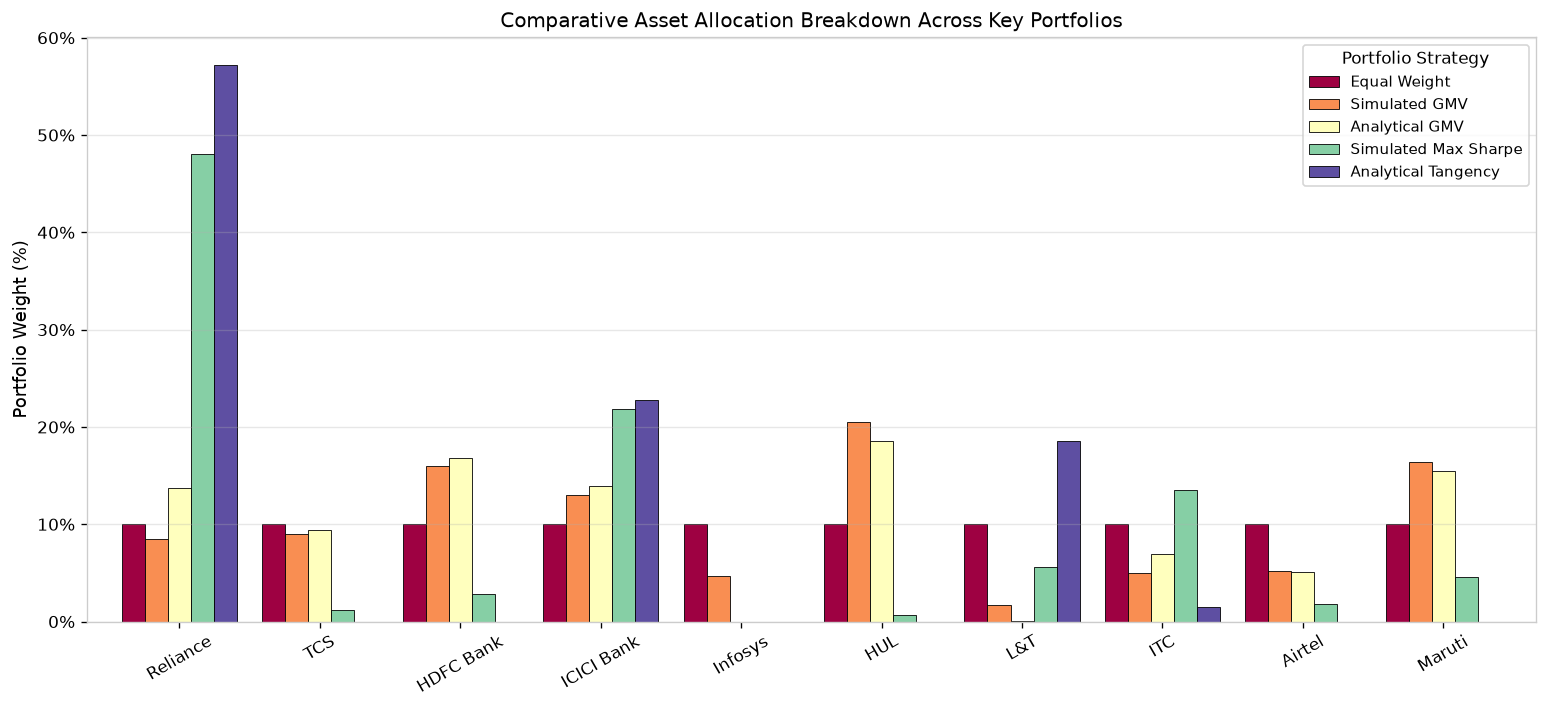

Asset Weights Breakdown (%):
            Equal Weight  Simulated GMV  Analytical GMV  Simulated Max Sharpe  Analytical Tangency
Reliance            10.0           8.45           13.74                 48.04                57.20
TCS                 10.0           9.04            9.41                  1.14                 0.00
HDFC Bank           10.0          15.99           16.81                  2.80                 0.00
ICICI Bank          10.0          13.02           13.98                 21.80                22.75
Infosys             10.0           4.67            0.00                  0.00                 0.00
HUL                 10.0          20.48           18.54                  0.69                 0.00
L&T                 10.0           1.76            0.03                  5.61                18.56
ITC                 10.0           5.03            6.99                 13.48                 1.49
Airtel              10.0           5.21            5.05                  1.83   

In [17]:
# Visualization 7: Selected Portfolio Asset Allocations Bar Chart
alloc_df = pd.DataFrame({
    'Equal Weight'       : eq_weights * 100,
    'Simulated GMV'      : mc_result.simulated_gmv.weights.values * 100,
    'Analytical GMV'     : analytical_gmv.weights.values * 100,
    'Simulated Max Sharpe': mc_result.simulated_max_sharpe.weights.values * 100,
    'Analytical Tangency': analytical_tangency.weights.values * 100,
}, index=[TICKER_LABELS[t] for t in TICKERS])

fig, ax = plt.subplots(figsize=(13, 6))
alloc_df.plot(kind='bar', ax=ax, width=0.82, colormap='Spectral', edgecolor='black', linewidth=0.5)

ax.set_title('Comparative Asset Allocation Breakdown Across Key Portfolios', fontsize=12)
ax.set_ylabel('Portfolio Weight (%)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(100))
ax.tick_params(axis='x', rotation=30)
ax.legend(title='Portfolio Strategy', fontsize=9, title_fontsize=10)
ax.grid(axis='y', alpha=0.3)

# Highlight concentration differences
plt.tight_layout()
plt.show()

print("Asset Weights Breakdown (%):")
print(alloc_df.round(2).to_string())


---
## 11. Rigorous Validation Checks Suite

We perform exhaustive automated verification covering:
1. Simplex dimensional integrity and weight finiteness.
2. Long-only constraint ($w_{k,i} \ge 0$) and budget constraint ($\sum_i w_{k,i} = 1$).
3. Return and volatility finiteness with non-negative variances.
4. Mathematical consistency of vectorized Sharpe ratio evaluation.
5. Analytical GMV and Tangency feasibility on the simplex.
6. Analytical frontier consistency (GMV volatility $\le$ Tangency volatility).
7. Seed reproducibility: re-executing `simulate_monte_carlo_portfolios` with seed 42 produces bitwise-identical arrays.
8. Analytical dominance:
   $$\sigma_{MC\_GMV} \ge \sigma_{GMV}^* - 10^{-7}, \quad SR_{MC\_MAX} \le SR_T^* + 10^{-7}$$
9. Frontier boundary verification via `validate_monte_carlo_against_frontier` (confirming all 10,000 simulated portfolios satisfy the boundary condition against the 100-point analytical grid within the configured $10^{-4}$ tolerance).
10. Calendar regression checks.


In [18]:
PASS_SYMBOL = "✓"
FAIL_SYMBOL = "✗"
results = []

def check(name: str, condition: bool, detail: str = "") -> None:
    symbol = PASS_SYMBOL if condition else FAIL_SYMBOL
    results.append((name, condition, detail))
    print(f"  {symbol}  {name}" + (f"  —  {detail}" if detail else ""))

print("Backend & Monte Carlo Validation Checks")
print("=" * 65)

# 1. Weight matrix dimensions
check("Weight matrix dimensions", sim_weights.shape == (NUM_SIMULATIONS, len(TICKERS)),
      f"shape = {sim_weights.shape}")

# 2. All weights finite
check("All weights finite", bool(np.isfinite(sim_weights).all()))

# 3. Long-only constraint
check("Long-only non-negativity constraint", bool((sim_weights >= 0.0).all()),
      f"min weight = {sim_weights.min():.6e}")

# 4. Budget constraint (weights sum to 1)
weight_sums = sim_weights.sum(axis=1)
check("Simplex budget constraint (sum w_i = 1.0)",
      bool(np.allclose(weight_sums, 1.0, atol=1e-6)),
      f"max deviation = {np.max(np.abs(weight_sums - 1.0)):.2e}")

# 5. Expected returns and volatilities finite
check("Expected returns finite", bool(np.isfinite(sim_returns).all()))
check("Volatilities finite", bool(np.isfinite(sim_vols).all()))

# 6. Non-negative variances
check("Variances non-negative", bool((mc_result.variances >= 0.0).all()))

# 7. Sharpe ratio vectorized consistency
recomputed_sharpes = (sim_returns - RISK_FREE_RATE) / sim_vols
check("Vectorized Sharpe ratio consistency",
      bool(np.allclose(sim_sharpes, recomputed_sharpes, atol=1e-8)),
      f"max diff = {np.max(np.abs(sim_sharpes - recomputed_sharpes)):.2e}")

# 8. Analytical GMV feasibility
check("Analytical GMV feasibility",
      bool(analytical_gmv.success and np.isclose(analytical_gmv.weights.sum(), 1.0) and (analytical_gmv.weights.values >= -1e-7).all()))

# 9. Analytical Tangency feasibility
check("Analytical Tangency feasibility",
      bool(analytical_tangency.success and np.isclose(analytical_tangency.weights.sum(), 1.0) and (analytical_tangency.weights.values >= -1e-7).all()))

# 10. Analytical frontier consistency
check("Analytical frontier volatility ordering",
      bool(analytical_gmv_vol <= analytical_tangency.volatility + 1e-6),
      f"GMV={analytical_gmv_vol:.2%} <= Tangency={analytical_tangency.volatility:.2%}")

# 11. Seed reproducibility check
repro_result = simulate_monte_carlo_portfolios(
    expected_returns=MU,
    covariance=COV,
    num_portfolios=NUM_SIMULATIONS,
    risk_free_rate=RISK_FREE_RATE,
    random_seed=RANDOM_SEED,
)
check("Deterministic seed reproducibility",
      bool(np.array_equal(sim_weights, repro_result.weights) and np.array_equal(sim_vols, repro_result.volatilities)),
      "bitwise-identical output with seed=42")

# 12. Analytical dominance: simulation cannot outperform analytical GMV
check("Analytical GMV dominance over simulated GMV",
      bool(mc_result.simulated_gmv.volatility >= analytical_gmv_vol - 1e-7),
      f"MC GMV={mc_result.simulated_gmv.volatility:.4%} >= Opt GMV={analytical_gmv_vol:.4%}")

# 13. Analytical dominance: simulation cannot outperform analytical Tangency Sharpe
check("Analytical Tangency dominance over simulated Max Sharpe",
      bool(mc_result.simulated_max_sharpe.sharpe_ratio <= analytical_tangency.sharpe_ratio + 1e-7),
      f"MC Max SR={mc_result.simulated_max_sharpe.sharpe_ratio:.4f} <= Opt SR={analytical_tangency.sharpe_ratio:.4f}")

# 14. Frontier envelope verification
check("Frontier validation: zero breaches against 100-point analytical grid",
      bool(validation_report.is_valid and validation_report.num_breaches == 0),
      f"all {validation_report.num_portfolios_tested:,} sampled portfolios passed within tolerance")

# 15-20. Calendar regression checks
check("Calendar: Saturday maps to previous trading day", cal_reg_sat == date(2026, 1, 23))
check("Calendar: Sunday maps to previous trading day", cal_reg_sun == date(2026, 1, 23))
check("Calendar: Weekday holiday maps to previous trading day", cal_reg_hol == date(2026, 1, 23))
check("Calendar: Weekday before 16:00 IST maps to previous trading day", cal_reg_pre == date(2026, 1, 23))
check("Calendar: Weekday after 16:00 IST maps to completed session", cal_reg_post == date(2026, 1, 27))
check("Data cutoff: latest observation aligns with completed session", prices.index[-1].date() == END_DATE,
      f"{prices.index[-1].date()} == {END_DATE}")

print()
passed = sum(1 for _, ok, _ in results if ok)
failed = sum(1 for _, ok, _ in results if not ok)
print(f"Results: {passed} passed, {failed} failed out of {len(results)} checks.")
if failed > 0:
    print("\nFailed checks:")
    for name, ok, detail in results:
        if not ok:
            print(f"  {FAIL_SYMBOL} {name}: {detail}")


Backend & Monte Carlo Validation Checks
  ✓  Weight matrix dimensions  —  shape = (10000, 10)
  ✓  All weights finite
  ✓  Long-only non-negativity constraint  —  min weight = 4.128894e-06
  ✓  Simplex budget constraint (sum w_i = 1.0)  —  max deviation = 5.55e-16
  ✓  Expected returns finite
  ✓  Volatilities finite
  ✓  Variances non-negative
  ✓  Vectorized Sharpe ratio consistency  —  max diff = 0.00e+00
  ✓  Analytical GMV feasibility
  ✓  Analytical Tangency feasibility
  ✓  Analytical frontier volatility ordering  —  GMV=12.76% <= Tangency=16.83%
  ✓  Deterministic seed reproducibility  —  bitwise-identical output with seed=42
  ✓  Analytical GMV dominance over simulated GMV  —  MC GMV=12.8823% >= Opt GMV=12.7629%
  ✓  Analytical Tangency dominance over simulated Max Sharpe  —  MC Max SR=0.8053 <= Opt SR=0.9067
  ✓  Frontier validation: zero breaches against 100-point analytical grid  —  all 10,000 sampled portfolios passed within tolerance
  ✓  Calendar: Saturday maps to previo

---
## 12. Research Findings, Interpretation & Methodological Conclusions

### 1. The Geometry of the Feasible Set
Monte Carlo simulation illustrates the convex nature of the portfolio feasible set in risk-return space. All 10,000 sampled portfolios passed validation against the computed analytical frontier grid within the configured numerical tolerance ($\epsilon = 10^{-4}$). The continuous analytical frontier forms the theoretical boundary of the feasible risk-return set.

### 2. Inefficiency of Random Heuristic Portfolios
The vast majority of random portfolios cluster in the interior of the feasible set. For any randomly selected interior portfolio $(\sigma_{	ext{rand}}, \mu_{	ext{rand}})$, there exists an analytical frontier portfolio with:
- Strictly higher expected return for the same level of risk, or
- Strictly lower volatility for the same expected return.
Heuristic or naive random allocations are almost universally Pareto-inefficient relative to the analytical boundary.

### 3. Precision of Convex Optimization vs. Random Sampling
While 10,000 Monte Carlo simulations provide an informative empirical overview of the feasible set, the simulated GMV ($\sigma = 12.88\%$) and simulated Max Sharpe ($SR = 0.81$) remain inferior to their analytical counterparts ($\sigma_{GMV}^* = 12.76\%$, $SR_T^* = 0.91$), with an observed GMV volatility gap of ~12 bps and a Sharpe gap of ~10 bps. In high dimensions ($N=10$), random sampling rarely approximates the specific weight combinations that characterize optimal boundary allocations. Analytical optimization (SLSQP / quadratic programming) is mathematically required for precision portfolio construction.

### 4. Diversification Benefits
Both the simulated cloud and the analytical GMV allocation demonstrate the power of portfolio diversification:
- Minimum individual constituent asset volatility: **19.78%** (`ITC.NS`)
- Analytical GMV volatility: **12.76%**
- Over 700 basis points of risk reduction achieved through covariance diversification without sacrificing long-only constraints.

### 5. Methodological Limitations & Forward Caveats
- **Sample Mean Sensitivity**: Historical returns over a 5-year sample window contain estimation noise. Past returns are not predictive of future performance.
- **Stationarity Assumption**: Covariance and correlation matrices shift over market regimes. Regularization (Ledoit-Wolf shrinkage) mitigates sample error but does not eliminate non-stationarity.
- **Execution Frictions**: Markowitz MVO assumes friction-free rebalancing with zero transaction costs and impact costs. Real-world execution requires turnover controls and slippage penalties.


In [19]:
# Appendix: Environment & Package Versions
import sys
import sklearn

print("=" * 65)
print("Quantamental AI Research Engine — Dependency Manifest")
print("=" * 65)
print(f"  Python           : {sys.version.split()[0]}")
print(f"  NumPy            : {np.__version__}")
print(f"  Pandas           : {pd.__version__}")
print(f"  SciPy            : {stats.scipy.__version__ if hasattr(stats, 'scipy') else 'installed'}")
print(f"  Scikit-Learn     : {sklearn.__version__}")
print(f"  Matplotlib       : {matplotlib.__version__}")
print(f"  Seaborn          : {sns.__version__}")
print(f"  YFinance         : {yf.__version__}")
print(f"  Repository Root  : {REPO_ROOT}")
print(f"  Latest Session   : {END_DATE}")
print("=" * 65)


Quantamental AI Research Engine — Dependency Manifest
  Python           : 3.12.5
  NumPy            : 2.5.5
  Pandas           : 2.2.3
  SciPy            : installed
  Scikit-Learn     : 1.9.1
  Matplotlib       : 3.11.2
  Seaborn          : 0.13.2
  YFinance         : 0.2.66
  Repository Root  : /Users/lakshyabapna/Desktop/Quantamental_AI
  Latest Session   : 2026-11-23
